# Прототип книжных рекомендаций на Goodbooks-10k

In [ ]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
from threadpoolctl import threadpool_limits

DATA_DIR = Path("data")
SEED = 42
K = 10
RELEVANCE = 4

## 1. Что лежит в данных

 Чтобы найти название по оценке, необходимо связать `ratings.book_id` с `books.id`. Чтобы найти теги, берём Goodreads ID из `books.book_id`. У каждого тега есть `count`. Он показывает, сколько раз этот тег присвоили конкретной книге.

В `ratings.csv` попадаются повторы - одинаковые строки удаляем, а если один читатель поставил книге разные оценки берём среднее.

In [ ]:
def load_data(root="data"):
    root = Path(root)
    if not (root / "ratings.csv").is_file():
        root /= "archive"

    ratings = pd.read_csv(
        root / "ratings.csv",
        dtype={"user_id": "int32", "book_id": "int32", "rating": "int8"},
    )
    books = pd.read_csv(
        root / "books.csv",
        usecols=["id", "book_id", "original_title", "title", "authors", "ratings_count"],
    ).rename(columns={"book_id": "goodreads_book_id", "id": "book_id"})
    books = books.set_index("book_id", verify_integrity=True).sort_index()
    tags = pd.read_csv(root / "tags.csv")
    book_tags = pd.read_csv(root / "book_tags.csv")

    if not ratings["rating"].between(1, 5).all() or not ratings["book_id"].isin(books.index).all():
        raise ValueError("В ratings.csv есть оценки вне шкалы 1–5 или неизвестные книги")
    return ratings, books, tags, book_tags


def prepare_ratings(raw_ratings):
    """Удаление одинаковых строк и усреденения."""
    return (
        raw_ratings.drop_duplicates()
        .groupby(["user_id", "book_id"], as_index=False, sort=False)["rating"]
        .mean()
        .astype({"rating": "float32"})
    )


def split_ratings(ratings, fraction=0.2, seed=42):
    """Случайный холдаут внутри каждого пользователя с сохранением в train-истории."""
    if not 0 < fraction < 1:
        raise ValueError("Доля теста должна быть между 0 и 1")
    shuffled = ratings.sample(frac=1, random_state=seed)
    groups = shuffled.groupby("user_id", sort=False)
    sizes = groups["rating"].transform("size")
    test_sizes = np.minimum(np.maximum(1, np.floor(sizes * fraction)), sizes - 1)
    is_test = groups.cumcount() < test_sizes
    return shuffled.loc[~is_test].reset_index(drop=True), shuffled.loc[is_test].reset_index(drop=True)

In [ ]:
raw_ratings, books, tags, book_tags = load_data(DATA_DIR)
ratings = prepare_ratings(raw_ratings)
display(pd.Series({
    "Строки в ratings.csv": len(raw_ratings),
    "Уникальные пары пользователь–книга": len(ratings),
    "Пользователи": ratings["user_id"].nunique(),
    "Книги": len(books),
    "Уникальные теги": len(tags),
    "Связи книга–тег": len(book_tags),
}, name="Количество").to_frame())

/var/folders/9c/p_z6c2m52pn71250yf4hc6500000gn/T/ipykernel_2818/3244759802.py:14: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  books = books.set_index("book_id", verify_integrity=True).sort_index()


,Количество
Строки в ratings.csv,981756
Уникальные пары пользователь–книга,979478
Пользователи,53424
Книги,10000
Уникальные теги,34252
Связи книга–тег,999912


In [ ]:
rating_counts = raw_ratings["rating"].value_counts().reindex(range(1, 6), fill_value=0)
user_activity = ratings.groupby("user_id").size()
book_activity = ratings.groupby("book_id").size().reindex(books.index, fill_value=0)
top_tags = (
    book_tags.groupby("tag_id")["count"].sum().nlargest(12)
    .rename("count").to_frame().join(tags.set_index("tag_id"))
)
top_one_percent = max(1, int(np.ceil(len(books) * 0.01)))
goodreads_activity = books["ratings_count"]
density = len(ratings) / (len(user_activity) * len(books))

display(pd.Series({
    "Доля оценок 4–5": f"{rating_counts.loc[4:].sum() / len(raw_ratings):.2%}",
    "Заполненность матрицы пользователь–книга": f"{density:.3%}",
    "Доля пользователей с ≤ 5 оценками": f"{user_activity.le(5).mean():.2%}",
    "Доля пользователей с ≥ 50 оценками": f"{user_activity.ge(50).mean():.2%}",
    "Медиана оценок на пользователя": f"{user_activity.median():.0f}",
    "Максимум оценок на пользователя": f"{user_activity.max():,}",
    "Медиана оценок на книгу": f"{book_activity.median():.0f}",
    "Книги с ровно 100 оценками в ratings.csv": f"{book_activity.eq(100).sum():,}",
    "Доля оценок у 1% книг (ratings.csv)": f"{book_activity.nlargest(top_one_percent).sum() / len(ratings):.2%}",
    "Доля оценок у 1% книг (Goodreads)": f"{goodreads_activity.nlargest(top_one_percent).sum() / goodreads_activity.sum():.2%}",
}, name="Значение").to_frame())

display(user_activity.nlargest(5).rename("Оценки").to_frame())
display(books.nlargest(5, "ratings_count")[["title", "authors", "ratings_count"]]
        .rename(columns={"ratings_count": "Оценки на Goodreads"}))

,Значение
Доля оценок 4–5,66.24%
Заполненность матрицы пользователь–книга,0.183%
Доля пользователей с ≤ 5 оценками,39.28%
Доля пользователей с ≥ 50 оценками,9.19%
Медиана оценок на пользователя,8
Максимум оценок на пользователя,200
Медиана оценок на книгу,100
Книги с ровно 100 оценками в ratings.csv,"6,248"
Доля оценок у 1% книг (ratings.csv),1.02%
Доля оценок у 1% книг (Goodreads),23.42%


,Оценки
user_id,
12874,200
30944,200
12381,199
28158,199
52036,199


,title,authors,Оценки на Goodreads
book_id,,,
1,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,4780653
2,Harry Potter and the Sorcerer's Stone (Harry P...,"J.K. Rowling, Mary GrandPré",4602479
3,"Twilight (Twilight, #1)",Stephenie Meyer,3866839
4,To Kill a Mockingbird,Harper Lee,3198671
5,The Great Gatsby,F. Scott Fitzgerald,2683664


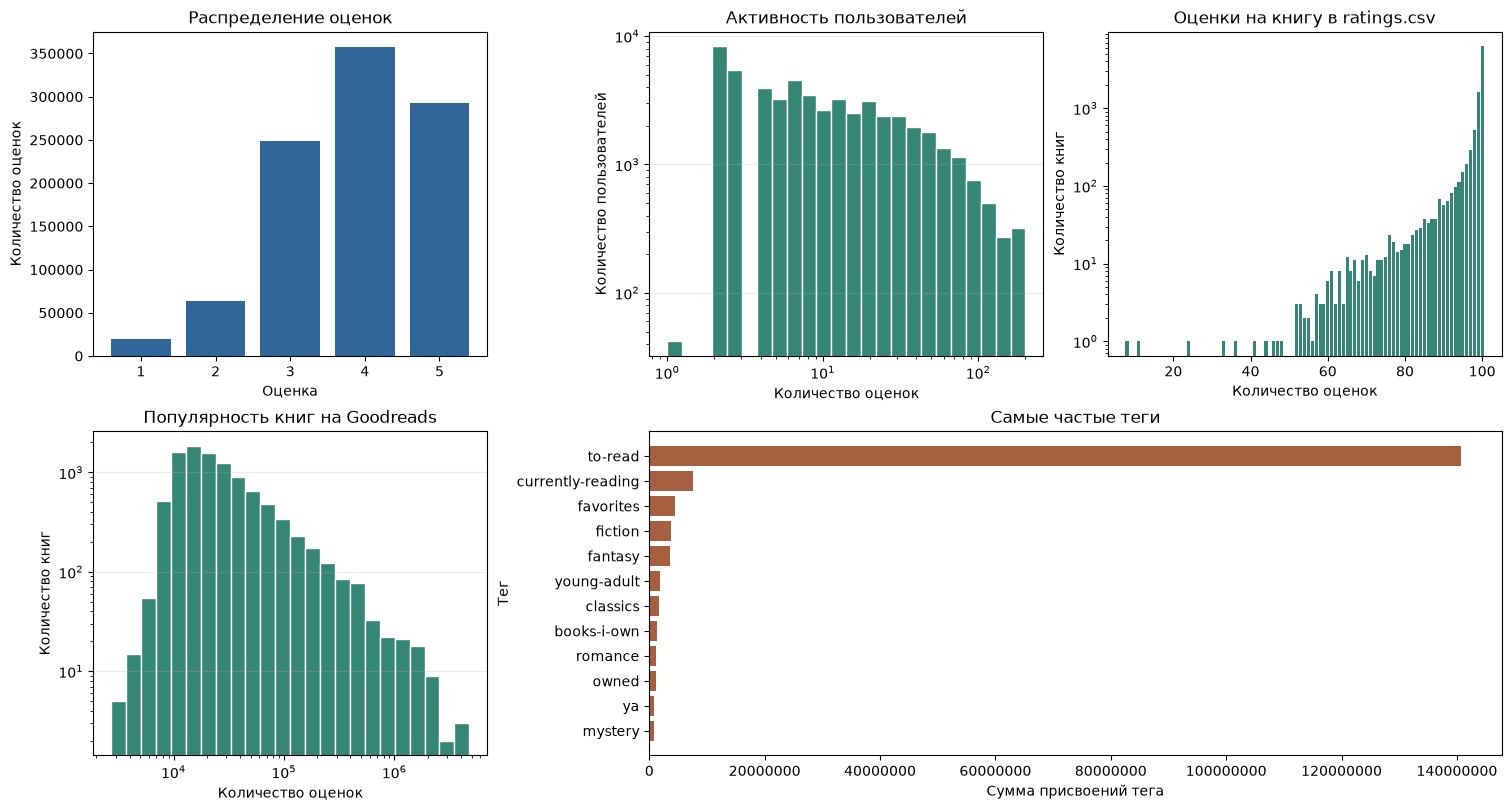

In [ ]:
fig, axes = plt.subplot_mosaic(
    [["ratings", "users", "sample"], ["goodreads", "tags", "tags"]],
    figsize=(15, 8), layout="constrained",
)

axes["ratings"].bar(rating_counts.index, rating_counts, color="#31669a")
axes["ratings"].set(title="Распределение оценок", xlabel="Оценка", ylabel="Количество оценок",
                    xticks=rating_counts.index)

for name, counts, title, label in [
    ("users", user_activity, "Активность пользователей", "Количество пользователей"),
    ("goodreads", goodreads_activity, "Популярность книг на Goodreads", "Количество книг"),
]:
    bins = np.geomspace(counts.min(), counts.max() + 1, 25)
    axes[name].hist(counts, bins=bins, color="#368676", edgecolor="white")
    axes[name].set(title=title, xlabel="Количество оценок", ylabel=label,
                   xscale="log", yscale="log")
    axes[name].grid(axis="y", alpha=0.25)

books_by_count = book_activity.value_counts().sort_index()
axes["sample"].bar(books_by_count.index, books_by_count, color="#368676")
axes["sample"].set(title="Оценки на книгу в ratings.csv", xlabel="Количество оценок",
                   ylabel="Количество книг", yscale="log")

ordered_tags = top_tags.iloc[::-1]
axes["tags"].barh(ordered_tags["tag_name"], ordered_tags["count"], color="#a65f3f")
axes["tags"].set(title="Самые частые теги", xlabel="Сумма присвоений тега", ylabel="Тег")
axes["tags"].ticklabel_format(axis="x", style="plain")
plt.show()

- По первому графику видно что читатели чаще ставят высокие оценки. При этом в матрице «читатель — книга» заполнено всего 0,183% ячеек.
- У 39,28% читателей пять оценок или меньше, а у 9,19% — 50 и больше. Если про читателя известно так мало, угадать его вкусы сложнее. Длинные истории, наоборот, дают больше примеров того, какие книги люди оценивают вместе.

- По `ratings.csv` трудно судить о популярности книг. У 6248 книг ровно 100 оценок, и на этом числе распределение обрывается. На самый популярный 1% книг приходится только 1,02% оценок в файле.
- По счётчику Goodreads из `books.csv` картина другая. Там 1% книг набрал 23,42% всех оценок. Этот счётчик берём только для графика и анализа.

- Самый частый тег `to-read`. Он говорит о планах читателя, а про саму книгу почти ничего. У тегов, которые встречаются у многих книг, вес в TF-IDF ниже.

## 2. Как дальше делим данные

У каждого читателя случайно откладываем около 20% оценок в test. Если оценок хотя бы две, в каждой части остаётся минимум одна. Поскольку в файле нет дат, проверяем, умеет ли модель восстановить случайно скрытые оценки. Средние рейтинги, соседей и факторы считаем на train. Названия и теги берём для всего каталога.

In [ ]:
def _top_positions(scores, n):
    """Позиции с конечными оценками по убыванию. При равенстве побеждает меньшая позиция."""
    if n <= 0:
        raise ValueError("N должно быть положительным")
    positions = np.flatnonzero(np.isfinite(scores))
    return positions[np.argsort(-scores[positions], kind="stable")[:n]]


def _item_graph(ratings, neighbors=150, block_size=256, shrinkage=10):
    """Ориентированный top-M граф: косинус по явным оценкам со штрафом за малое пересечение."""
    vectors = normalize(ratings.T.tocsr(), norm="l2")
    observed = vectors.copy()
    observed.data.fill(1)
    vectors_t, observed_t = vectors.T.tocsr(), observed.T.tocsr()
    blocks = []

    for start in range(0, ratings.shape[1], block_size):
        similarity = vectors[start : start + block_size] @ vectors_t
        overlap = observed[start : start + block_size] @ observed_t
        similarity.sort_indices()
        overlap.sort_indices()
        similarity.data *= overlap.data / (overlap.data + shrinkage)
        row_indices, col_indices, values = [], [], []

        for row in range(similarity.shape[0]):
            left, right = similarity.indptr[row : row + 2]
            columns = similarity.indices[left:right]
            scores = similarity.data[left:right]
            scores[columns == start + row] = -np.inf
            keep = _top_positions(scores, neighbors)
            row_indices.extend([row] * len(keep))
            col_indices.extend(columns[keep])
            values.extend(scores[keep])

        blocks.append(
            sparse.csr_matrix(
                (np.asarray(values, dtype=np.float32), (row_indices, col_indices)),
                shape=similarity.shape,
            )
        )

    return sparse.vstack(blocks, format="csc")

In [ ]:
class BookRecommender:
    MODELS = ("Popularity", "Content-Based", "Item-Based CF", "SVD")

    def __init__(self, books, tags, book_tags, train, *, min_ratings=50, factors=40, seed=42):
        self.books = books
        self.users = pd.Index(np.sort(train["user_id"].unique()))
        rows = self.users.get_indexer(train["user_id"])
        cols = self.books.index.get_indexer(train["book_id"])
        values = train["rating"].to_numpy(dtype=np.float32)
        self.ratings = sparse.csr_matrix(
            (values, (rows, cols)), shape=(len(self.users), len(books))
        )

        self.item_count = np.bincount(cols, minlength=len(books))
        item_sum = np.bincount(cols, weights=values, minlength=len(books))
        self.global_mean = float(values.mean())
        self.item_mean = np.divide(
            item_sum, self.item_count, out=np.full(len(books), self.global_mean),
            where=self.item_count > 0,
        ).astype(np.float32)
        self.popularity = np.where(self.item_count >= min_ratings, self.item_mean, -np.inf)
        self.graph = _item_graph(self.ratings)

        # item bias и user bias со сглаживанием по числу оценок.
        self.item_bias = ((item_sum - self.item_count * self.global_mean) /
                          (self.item_count + 15)).astype(np.float32)
        item_residual = values - self.global_mean - self.item_bias[cols]
        self.user_bias = (
            np.bincount(rows, weights=item_residual, minlength=len(self.users)) /
            (np.bincount(rows, minlength=len(self.users)) + 10)
        ).astype(np.float32)
        centered = sparse.csr_matrix(
            (item_residual - self.user_bias[rows], (rows, cols)), shape=self.ratings.shape
        )
        svd = TruncatedSVD(n_components=min(factors, min(centered.shape)), n_iter=7, random_state=seed)
        self.user_factors = svd.fit_transform(centered)
        self.item_factors = np.ascontiguousarray(svd.components_.T)

        # ratings.book_id соответствует books.id. Теги соединяются по внешнему Goodreads ID.
        frequent_tags = (
            book_tags.loc[book_tags["count"] > 0]
            .sort_values(["count", "tag_id"], ascending=[False, True])
            .groupby("goodreads_book_id", sort=False)
            .head(30)
            .merge(tags, on="tag_id", validate="many_to_one")
        )
        tag_text = frequent_tags.groupby("goodreads_book_id")["tag_name"].agg(" ".join)
        titles = books["original_title"].fillna(books["title"]).fillna("")
        profiles = titles + " " + books["goodreads_book_id"].map(tag_text).fillna("")
        self.content = TfidfVectorizer(
            dtype=np.float32, sublinear_tf=True, token_pattern=r"(?u)\b[\w-]+\b",
        ).fit_transform(profiles)

    def _history(self, user):
        if user < 0:
            return np.empty(0, dtype=int), np.empty(0, dtype=np.float32)
        start, stop = self.ratings.indptr[user : user + 2]
        return self.ratings.indices[start:stop], self.ratings.data[start:stop]

    def _content_scores(self, positive):
        if not len(positive):
            return self.popularity.copy()
        profile = normalize(sparse.csr_matrix(self.content[positive].sum(axis=0)))
        scores = (self.content @ profile.T).toarray().ravel()
        # При отсутствии текстового сходства используем порядок популярности.
        return np.where(scores > 0, scores, self.popularity - 6)

    def _cf_scores(self, seen, ratings, k=20):
        if k <= 0:
            raise ValueError("K должно быть положительным")
        edges = self.graph[:, seen].tocoo()
        scores = self.item_mean.copy()
        if not edges.nnz:
            return scores

        # Группируем соседей каждой книги, упорядочивая по убыванию сходства.
        order = np.lexsort((edges.col, -edges.data, edges.row))
        rows = edges.row[order]
        first = np.r_[True, rows[1:] != rows[:-1]]
        positions = np.arange(len(rows))
        keep = positions - np.maximum.accumulate(np.where(first, positions, 0)) < k
        selected = order[keep]
        targets = edges.row[selected]
        weights = edges.data[selected]
        residuals = ratings - self.item_mean[seen]
        weight_sum = np.bincount(targets, weights=weights, minlength=len(scores))
        weighted_residuals = np.bincount(
            targets, weights=weights * residuals[edges.col[selected]], minlength=len(scores)
        )
        has_neighbors = weight_sum > 0
        scores[has_neighbors] += weighted_residuals[has_neighbors] / weight_sum[has_neighbors]
        return scores

    def _svd_scores(self, user):
        if user < 0:
            return self.global_mean + self.item_bias
        return (self.global_mean + self.user_bias[user] + self.item_bias +
                self.item_factors @ self.user_factors[user])

    def recommend(self, user_id, N=5, *, model="SVD", threshold=4):
        """Массив внутренних идентификаторов книг в порядке рекомендации."""
        user = self.users.get_indexer([user_id])[0]
        seen, ratings = self._history(user)
        if model == "Popularity":
            scores = self.popularity.copy()
        elif model == "Content-Based":
            scores = self._content_scores(seen[ratings >= threshold])
        elif model == "Item-Based CF":
            scores = self._cf_scores(seen, ratings)
        elif model == "SVD":
            scores = self._svd_scores(user)
        else:
            raise ValueError(f"Неизвестная модель: {model}")

        if model in ("Item-Based CF", "SVD"):
            scores[self.item_count == 0] = -np.inf
        scores[seen] = -np.inf
        return self.books.index.to_numpy()[_top_positions(scores, N)]

    def get_similar_books(self, book_id, N=5):
        """Топ-N книг по косинусной близости TF-IDF, исключая книгу-запрос."""
        item = self.books.index.get_loc(book_id)
        scores = (self.content @ self.content[item].T).toarray().ravel()
        scores[item] = -np.inf
        keep = _top_positions(scores, N)
        result = self.books.iloc[keep][["title", "authors"]].copy()
        result["cosine_similarity"] = scores[keep]
        return result

    def get_recommendations(self, user_id, N=5):
        """Персональный топ-N по прогнозу SVD с названиями и авторами."""
        return self.books.loc[self.recommend(user_id, N), ["title", "authors"]]

    def predict_cf(self, user_id, book_id, K=20):
        """Прогноз оценки по K ближайшим книгам из истории пользователя."""
        user = self.users.get_indexer([user_id])[0]
        seen, ratings = self._history(user)
        item = self.books.index.get_loc(book_id)
        return float(np.clip(self._cf_scores(seen, ratings, K)[item], 1, 5))

    def predict_svd(self, pairs):
        """Пакетный прогноз оценок для известных пар из holdout."""
        rows = self.users.get_indexer(pairs["user_id"])
        cols = self.books.index.get_indexer(pairs["book_id"])
        if (rows < 0).any() or (cols < 0).any():
            raise ValueError("В пакете есть неизвестные пользователи или книги")
        predictions = np.empty(len(pairs), dtype=np.float32)
        for start in range(0, len(pairs), 8192):
            batch = slice(start, start + 8192)
            u, i = rows[batch], cols[batch]
            latent = np.einsum("ij,ij->i", self.user_factors[u], self.item_factors[i])
            predictions[batch] = self.global_mean + self.user_bias[u] + self.item_bias[i] + latent
        return np.clip(predictions, 1, 5)

In [ ]:
train, test = split_ratings(ratings, fraction=0.2, seed=SEED)
with threadpool_limits(limits=2):
    recommender = BookRecommender(books, tags, book_tags, train, min_ratings=50,
                                  factors=40, seed=SEED)

print(f"Train: {len(train):,} | Test: {len(test):,} ({len(test) / len(ratings):.1%})")
print(f"Размер CSR: {recommender.ratings.shape}, ненулевых элементов: {recommender.ratings.nnz:,}")
print(f"Книг без оценок в train: {np.count_nonzero(recommender.item_count == 0):,}")
print(f"Книг с ≥ 50 оценками в train: {np.isfinite(recommender.popularity).sum():,}")

Train: 788,503 | Test: 190,975 (19.5%)
Размер CSR: (53424, 10000), ненулевых элементов: 788,503
Книг без оценок в train: 0
Книг с ≥ 50 оценками в train: 9,909


## 3. Строим четыре модели

- **Popularity.** Берём книги, у которых в train есть хотя бы 50 оценок, и сортируем их по среднему рейтингу. Без порога книга с парой пятёрок легко обогнала бы книгу с сотней хороших оценок.

- **Content-Based.** Склеиваем название книги и до 30 её самых частых тегов. Если `original_title` пустое, берём `title`. Потом переводим текст в TF-IDF-вектор. Функция `get_similar_books` ищет книги, чьи векторы ближе всего по косинусной мере.

- **Item-Based CF.** Здесь сравниваем книги по оценкам читателей. Оценки храним в разреженной CSR-матрице. Если две книги оценили всего несколько общих читателей, их сходству доверяем меньше. Поэтому умножаем косинусное сходство на c/(c+10), где c — число общих оценок. Для прогноза берём до 20 ближайших соседей, которых читатель уже оценил. Смотрим, насколько его оценки выше или ниже средних по этим книгам, и добавляем взвешенное отклонение к средней оценке целевой книги. Если подходящих соседей нет, возвращаем среднюю оценку книги.

- **SVD.** Сначала вычитаем из оценок общее среднее и сглаженные смещения читателя и книги. Например, смещение помогает учесть, что один читатель часто ставит пятёрки, а другой редко. К разреженной матрице остатков применяем `TruncatedSVD` с 40 компонентами. В прогноз возвращаем среднее смещения и добавляем скалярное произведение факторов. На месте неизвестных остатков в матрице стоят нули, поэтому редкие оценки могут слабо влиять на факторы, а при расчёте RMSE обрезаем прогнозы до диапазона от 1 до 5.

In [ ]:
example_book = 1
example_user = int(recommender.users[0])

print("Популярные книги")
display(books.loc[recommender.recommend(None, model="Popularity"), ["title", "authors"]])

print("Книги, похожие на", books.loc[example_book, "title"])
display(recommender.get_similar_books(example_book, N=5))

print(f"Item-Based CF, прогноз оценки книги {example_book} пользователем {example_user}: "
      f"{recommender.predict_cf(example_user, example_book):.2f}")

print(f"Рекомендации SVD для пользователя {example_user}")
display(recommender.get_recommendations(example_user, N=5))

Популярные книги


,title,authors
book_id,,
7947,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem"
5207,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson
6920,The Indispensable Calvin and Hobbes,Bill Watterson
3275,"Harry Potter Boxed Set, Books 1-5 (Harry Potte...","J.K. Rowling, Mary GrandPré"
9566,Attack of the Deranged Mutant Killer Monster S...,Bill Watterson


Книги, похожие на The Hunger Games (The Hunger Games, #1)


,title,authors,cosine_similarity
book_id,,,
507,The Hunger Games Trilogy Boxset (The Hunger Ga...,Suzanne Collins,0.749029
20,"Mockingjay (The Hunger Games, #3)",Suzanne Collins,0.680511
6224,The World of the Hunger Games (Hunger Games Tr...,Kate Egan,0.648278
17,"Catching Fire (The Hunger Games, #2)",Suzanne Collins,0.594168
1355,The Hunger Games Tribute Guide,Emily Seife,0.538016


Item-Based CF, прогноз оценки книги 1 пользователем 1: 4.22
Рекомендации SVD для пользователя 1


,title,authors
book_id,,
6920,The Indispensable Calvin and Hobbes,Bill Watterson
5207,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson
9566,Attack of the Deranged Mutant Killer Monster S...,Bill Watterson
3275,"Harry Potter Boxed Set, Books 1-5 (Harry Potte...","J.K. Rowling, Mary GrandPré"
7947,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem"


## 4. Сравниваем модели

Берём одних и тех же 1000 читателей, у которых есть хотя бы одна книга с тестовой оценкой 4 или 5. Для каждого строим топ-10 по каталогу, убирая книги, которые он уже оценил в train. Метрики сначала считаем отдельно для каждого читателя, потом берём среднее.

- **Precision@K** показывает, какая доля мест в топе занята книгами, которые понравились. Число попаданий делим на $K$.
- **Recall@K** показывает, какую часть понравившихся книг из test нашла модель.
- **nDCG@K** учитывает порядок. Попадание на позиции r имеет вес 1\log_2(r+1). Сумму весов делим на результат идеальной выдачи, где первые min(K, |R_u|) мест занимают релевантные книги.
- **RMSE** показывает ошибку прогноза оценки. Берём корень из среднего квадрата ошибок по всем тестовым оценкам. Для сравнения считаем ту же метрику, если всегда предсказывать среднюю оценку книги из train.

In [ ]:
def ranking_metrics(recommended, relevant, k):
    """Бинарная релевантность. Пустые позиции занимают место в знаменателе Precision@K."""
    hits = np.isin(recommended[:k], relevant)
    discount = 1 / np.log2(np.arange(2, k + 2))
    dcg = hits @ discount[: len(hits)]
    ideal = discount[: min(k, len(relevant))].sum()
    return hits.sum() / k, hits.sum() / len(relevant), dcg / ideal


def evaluate(model, test, *, k=10, threshold=4, sample_size=1000, seed=42):
    """Macro-метрики на одной выборке пользователей для всех моделей."""
    relevant = test.loc[test["rating"] >= threshold].groupby("user_id")["book_id"].agg(list)
    sample = relevant.sample(n=min(sample_size, len(relevant)), random_state=seed)
    if sample.empty:
        raise ValueError("В тесте нет пользователей с релевантными оценками")
    scores = np.empty((len(sample), len(model.MODELS), 3))
    for index, (user, books) in enumerate(sample.items()):
        for column, name in enumerate(model.MODELS):
            recommendations = model.recommend(user, k, model=name, threshold=threshold)
            scores[index, column] = ranking_metrics(recommendations, books, k)

    results = pd.DataFrame(
        scores.mean(axis=0), index=model.MODELS,
        columns=[f"Precision@{k}", f"Recall@{k}", f"nDCG@{k}"],
    )
    results.index.name = "Модель"
    return results, len(sample), len(relevant)

In [ ]:
with threadpool_limits(limits=2):
    metrics, evaluated_users, eligible_users = evaluate(
        recommender, test, k=K, threshold=RELEVANCE, sample_size=1_000, seed=SEED
    )

actual = test["rating"].to_numpy()
svd_rmse = np.sqrt(np.mean((recommender.predict_svd(test) - actual) ** 2))
item_mean = recommender.item_mean[books.index.get_indexer(test["book_id"])]
item_mean_rmse = np.sqrt(np.mean((item_mean - actual) ** 2))

print(f"Оценено пользователей: {evaluated_users:,} из {eligible_users:,} с релевантными книгами в test")
display(metrics.sort_values(f"nDCG@{K}", ascending=False).round(5))
display(pd.Series({
    "SVD": svd_rmse,
    "Средняя оценка книги": item_mean_rmse,
}, name="RMSE").round(5).to_frame())

Оценено пользователей: 1,000 из 42,565 с релевантными книгами в test


,Precision@10,Recall@10,nDCG@10
Модель,,,
Content-Based,0.0433,0.17158,0.13145
Item-Based CF,0.0021,0.01700,0.00689
Popularity,0.0008,0.00316,0.00239
SVD,0.0009,0.00325,0.00208


,RMSE
SVD,0.84160
Средняя оценка книги,0.94834


## 5. Результаты

По всем трём метрикам лучше всего сработала **Content-Based** = **0,13145**. Это видно и на примере The Hunger Games. Модель находит продолжения и другие издания той же серии. При случайном разбиении часть серии может остаться в train, а часть попасть в test, так что результат хорошо показывает, как модель подбирает книги по знакомым темам и сериям.

Среди моделей, которые используют только оценки, первое место у **Item-Based CF** (nDCG@10 = **0,00689**). У SVD ошибка прогноза 0,84160. Для сравнения, если предсказывать средний рейтинг книги, получается **0,94834**. При этом по nDCG SVD уступила даже Popularity. Такое возможно, потому что RMSE проверяет точность по уже известным тестовым оценкам, а в рекомендациях нужно поставить нужную книгу выше тысяч других.

| Модель | Что получается хорошо | Где возникают сложности |
|---|---|---|
| Popularity | Можно сразу дать список новому читателю | Список общий для всех, а книги с малым числом оценок не проходят порог |
| Content-Based | Можно найти похожую книгу, даже если у неё пока нет оценок | Общие теги иногда дают слабые подсказки, а похожие названия сужают выбор |
| Item-Based CF | Можно объяснить рекомендацию через книги которые читатель уже оценил | Нужны общие читатели у книг |
| SVD | Факторы занимают мало места и позволяют быстро считать прогнозы | Для новых книг и читателей нужен запасной вариант, но точный прогноз оценки ещё не гарантирует хороший топ |

### На будующее

Новому читателю можно сначала показать популярные книги и попросить выбрать несколько любимых. По ним уже получится собрать контентный профиль и предложить похожие книги, в том числе совсем новые. Когда накопится история, можно попробовать объединить порядок книг в контентной выдаче и SVD. Сравнивать места проще, чем складывать косинусное сходство с предсказанным рейтингом. Чем больше оценок у читателя и книги, тем больше веса можно дать SVD. Для новых книг можно оставить отдельное место в выдаче. Порог и веса стоит подобрать на валидации. В train этого прогона есть все 10 000 книг, поэтому для проверки холодного старта нужно целиком отложить оценки части книг.

Ещё можно добавить к названиям и тегам описания, авторов и многоязычные эмбеддинги. Для моделей по оценкам имеет смысл попробовать факторизацию только по наблюдаемым оценкам и отдельно модель, которая сразу учится ранжировать. При проверке гибрида интересно посмотреть, помогает ли он читателям с короткой историей и чаще ли показывает книги из длинного хвоста. Если появятся даты оценок, можно будет разделить данные по времени.